# Prediksi Kualitas Wine Menggunakan Machine Learning

## 1. Pendahuluan

Notebook ini bertujuan untuk membangun dan mengevaluasi model Machine Learning dalam memprediksi kualitas wine berdasarkan karakteristik fisikokimia. Dataset yang digunakan merupakan hasil prapemrosesan pada tahap sebelumnya.

Target prediksi adalah kolom `quality`, yang berisi skor kualitas wine dengan rentang nilai 3 hingga 9 pada dataset yang digunakan. Pendekatan regresi dipilih untuk memprediksi skor kualitas sebagai nilai numerik.

Eksperimen mencakup pemeriksaan dataset, analisis distribusi target, pembagian data latih dan data uji, pelatihan beberapa algoritma regresi, serta evaluasi dan perbandingan performa model.

In [20]:

# 2.1 Import library dan memuat dataset

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Lokasi dataset hasil prapemrosesan
data_path = Path(
    r"D:\MachineLearning\Wine\data\processed\winequality_cleaned.csv"
)

# Memastikan file tersedia
if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {data_path}"
    )

# Memuat dataset
df = pd.read_csv(data_path, sep=None, engine="python")

print("Dataset berhasil dimuat.")
print("Lokasi:", data_path)
print("Ukuran dataset:", df.shape)


Dataset berhasil dimuat.
Lokasi: D:\MachineLearning\Wine\data\processed\winequality_cleaned.csv
Ukuran dataset: (5320, 13)


In [21]:

# 2.2 Memeriksa struktur dataset

print("Nama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

print("\nJumlah missing values:")
display(df.isnull().sum())

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())


Nama kolom:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type']

Lima baris pertama:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  wine_type             5320 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 540.4 KB

Jumlah missing values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64


Jumlah baris duplikat:
0


## 3. Analisis Distribusi Target

Analisis distribusi target dilakukan untuk mengetahui frekuensi setiap skor kualitas wine. Tahap ini penting untuk memahami karakteristik target, mengidentifikasi ketidakseimbangan distribusi, dan menentukan metrik evaluasi yang sesuai.

In [22]:

# 3.1 Distribusi skor quality

quality_counts = df["quality"].value_counts().sort_index()

quality_distribution = pd.DataFrame({
    "Jumlah Data": quality_counts,
    "Persentase (%)": (
        quality_counts / len(df) * 100
    ).round(2)
})

display(quality_distribution)

print("Skor quality terendah:", df["quality"].min())
print("Skor quality tertinggi:", df["quality"].max())
print("Rata-rata quality:", round(df["quality"].mean(), 3))
print("Median quality:", df["quality"].median())
print("Standar deviasi quality:", round(df["quality"].std(), 3))


,Jumlah Data,Persentase (%)
quality,,
3,30,0.56
4,206,3.87
5,1752,32.93
6,2323,43.67
7,856,16.09
8,148,2.78
9,5,0.09


Skor quality terendah: 3
Skor quality tertinggi: 9
Rata-rata quality: 5.796
Median quality: 6.0
Standar deviasi quality: 0.88


In [23]:

# 4.1 Menentukan fitur dan target

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
]

X = df[feature_cols]
y = df["quality"]

print("Jumlah fitur:", len(feature_cols))
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

print("\nDistribusi target:")
print(y.value_counts().sort_index())


Jumlah fitur: 11
Bentuk X: (5320, 11)
Bentuk y: (5320,)

Distribusi target:
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


### 5. Pembagian Data Latih dan Data Uji

Dataset dibagi menjadi data latih sebesar 80% dan data uji sebesar 20% menggunakan fungsi `train_test_split` dengan `random_state=42`. Parameter `stratify=y` digunakan untuk mempertahankan proporsi setiap skor kualitas pada kedua subset.

Hasil pembagian menghasilkan 4.256 data latih dan 1.064 data uji. Proporsi skor kualitas pada data latih dan data uji relatif serupa, sehingga pembagian data tetap mencerminkan distribusi target pada dataset.

Skor kualitas 5 dan 6 mendominasi dataset, sedangkan skor 9 hanya memiliki lima sampel secara keseluruhan. Kondisi ini menjadi keterbatasan dalam mempelajari kualitas yang jarang ditemukan. Oleh karena itu, evaluasi model akan menggunakan beberapa metrik regresi dan hasilnya akan diinterpretasikan dengan mempertimbangkan distribusi target.

In [24]:

# 5.1 Membagi data latih dan data uji

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

print("\nBentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)
print("Bentuk y_train:", y_train.shape)
print("Bentuk y_test:", y_test.shape)

print("\nProporsi quality pada data latih:")
print(
    (y_train.value_counts(normalize=True).sort_index() * 100).round(2)
)

print("\nProporsi quality pada data uji:")
print(
    (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
)


Jumlah data latih: 4256
Jumlah data uji: 1064

Bentuk X_train: (4256, 11)
Bentuk X_test: (1064, 11)
Bentuk y_train: (4256,)
Bentuk y_test: (1064,)

Proporsi quality pada data latih:
quality
3     0.56
4     3.88
5    32.94
6    43.66
7    16.09
8     2.77
9     0.09
Name: proportion, dtype: float64

Proporsi quality pada data uji:
quality
3     0.56
4     3.85
5    32.89
6    43.70
7    16.07
8     2.82
9     0.09
Name: proportion, dtype: float64


In [25]:

# 7.1 Inisialisasi model regresi

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Model yang akan dievaluasi:")
for model_name in models:
    print("-", model_name)


Model yang akan dievaluasi:
- Linear Regression
- Decision Tree
- Random Forest


In [26]:

# 7.2 Pelatihan dan evaluasi awal model regresi

results = []
predictions = {}

for model_name, model in models.items():
    # Melatih model dengan data latih
    model.fit(X_train, y_train)

    # Memprediksi data uji
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    # Menghitung metrik regresi
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True).round(4)


,Model,MAE,RMSE,R2
0,Random Forest,0.5336,0.6908,0.3838
1,Linear Regression,0.5673,0.7335,0.3053
2,Decision Tree,0.6739,0.9834,-0.2486


### 8. Evaluasi Model Menggunakan Cross-Validation

Cross-validation digunakan untuk mengevaluasi kestabilan performa model melalui beberapa pembagian data latih. Pada eksperimen ini, digunakan metode 5-Fold Cross-Validation, yaitu data latih dibagi menjadi lima bagian. Secara bergantian, empat bagian digunakan untuk pelatihan dan satu bagian digunakan untuk validasi.

Evaluasi menggunakan MAE, RMSE, dan \(R^2\). Rata-rata metrik digunakan untuk membandingkan performa model, sedangkan simpangan baku MAE digunakan untuk mengamati variasi kesalahan antarfold. Data uji tidak digunakan dalam proses ini agar tetap dapat berfungsi sebagai evaluasi akhir yang independen.

In [27]:

# 8.1 Cross-validation untuk model regresi

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Skor MAE dan RMSE dari sklearn berupa nilai negatif
    # sehingga dikalikan -1 agar kembali menjadi nilai error positif
    mae_scores = -scores["test_mae"]
    rmse_scores = -scores["test_rmse"]
    r2_scores = scores["test_r2"]

    cv_results.append({
        "Model": model_name,
        "MAE Mean": mae_scores.mean(),
        "MAE Std": mae_scores.std(),
        "RMSE Mean": rmse_scores.mean(),
        "R2 Mean": r2_scores.mean(),
        "R2 Std": r2_scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    by="RMSE Mean",
    ascending=True
).reset_index(drop=True).round(4)


,Model,MAE Mean,MAE Std,RMSE Mean,R2 Mean,R2 Std
0,Random Forest,0.5343,0.0115,0.6965,0.3716,0.0164
1,Linear Regression,0.5644,0.0154,0.7334,0.3035,0.0155
2,Decision Tree,0.6842,0.0174,0.9973,-0.2886,0.0328


In [28]:

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor

# Konfigurasi dasar Random Forest
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

# Kombinasi parameter yang akan dicoba
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 15, 20, 25, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.7]
}

# Cross-validation 5-fold
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Pencarian parameter terbaik berdasarkan RMSE
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

# Proses tuning hanya pada data latih
rf_search.fit(X_train, y_train)

print("Parameter terbaik:")
print(rf_search.best_params_)

print(
    "\nBest CV RMSE:",
    round(-rf_search.best_score_, 4)
)


Parameter terbaik:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 25}

Best CV RMSE: 0.69


In [29]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Ambil model dengan parameter terbaik
best_rf = rf_search.best_estimator_

# Prediksi menggunakan data uji
y_pred_best_rf = best_rf.predict(X_test)

# Hitung metrik evaluasi
mae = mean_absolute_error(y_test, y_pred_best_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
r2 = r2_score(y_test, y_pred_best_rf)

# Tampilkan hasil
tuned_results = pd.DataFrame([{
    "Model": "Random Forest Tuned",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}])

tuned_results.round(4)


,Model,MAE,RMSE,R2
0,Random Forest Tuned,0.5265,0.6807,0.4019


In [30]:

comparison_df = pd.DataFrame([
    {
        "Model": "Random Forest Awal",
        "MAE": mean_absolute_error(
            y_test, predictions["Random Forest"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, predictions["Random Forest"]
        )),
        "R2": r2_score(
            y_test, predictions["Random Forest"]
        )
    },
    {
        "Model": "Random Forest Tuned",
        "MAE": mean_absolute_error(
            y_test, y_pred_best_rf
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, y_pred_best_rf
        )),
        "R2": r2_score(
            y_test, y_pred_best_rf
        )
    }
])

comparison_df.round(4)


,Model,MAE,RMSE,R2
0,Random Forest Awal,0.5336,0.6908,0.3838
1,Random Forest Tuned,0.5265,0.6807,0.4019


### Perbandingan Random Forest Sebelum dan Sesudah Hyperparameter Tuning

Hyperparameter tuning dilakukan menggunakan metode RandomizedSearchCV dengan skema 5-Fold Cross-Validation pada data latih. Proses ini bertujuan untuk menemukan kombinasi parameter Random Forest yang dapat meningkatkan performa prediksi kualitas wine.

Hasil evaluasi pada data uji menunjukkan bahwa Random Forest Tuned memperoleh MAE sebesar 0,5265, RMSE sebesar 0,6807, dan R² sebesar 0,4019. Hasil tersebut lebih baik dibandingkan Random Forest Awal yang memperoleh MAE sebesar 0,5336, RMSE sebesar 0,6908, dan R² sebesar 0,3838.

Penurunan nilai MAE dan RMSE menunjukkan bahwa kesalahan prediksi berkurang, sedangkan peningkatan R² menunjukkan bahwa kemampuan model dalam menjelaskan variasi nilai kualitas wine mengalami perbaikan. Meskipun demikian, nilai R² sebesar 0,4019 menunjukkan bahwa kemampuan prediksi model masih terbatas. Oleh karena itu, Random Forest Tuned dipilih sebagai kandidat model terbaik berdasarkan hasil eksperimen yang telah dilakukan, dengan tetap mempertimbangkan keterbatasan performanya.

In [31]:

error_analysis = pd.DataFrame({
    "Actual Quality": y_test.to_numpy(),
    "Predicted Quality": y_pred_best_rf
})

error_analysis["Absolute Error"] = (
    error_analysis["Actual Quality"]
    - error_analysis["Predicted Quality"]
).abs()

per_quality_results = (
    error_analysis
    .groupby("Actual Quality")
    .agg(
        Samples=("Absolute Error", "size"),
        MAE=("Absolute Error", "mean"),
        Mean_Prediction=("Predicted Quality", "mean")
    )
    .reset_index()
)

per_quality_results.round(3)


,Actual Quality,Samples,MAE,Mean_Prediction
0,3,6,2.352,5.352
1,4,41,1.255,5.255
2,5,350,0.430,5.423
3,6,465,0.384,5.837
4,7,171,0.676,6.325
5,8,30,1.550,6.450
6,9,1,3.434,5.566


In [32]:

per_quality_results = (
    error_analysis
    .groupby("Actual Quality")
    .agg(
        Samples=("Absolute Error", "size"),
        MAE=("Absolute Error", "mean"),
        Mean_Prediction=("Predicted Quality", "mean")
    )
    .reset_index()
)

per_quality_results = per_quality_results.round(3)

display(per_quality_results.to_string(index=False))


' Actual Quality  Samples   MAE  Mean_Prediction\n              3        6 2.352            5.352\n              4       41 1.255            5.255\n              5      350 0.430            5.423\n              6      465 0.384            5.837\n              7      171 0.676            6.325\n              8       30 1.550            6.450\n              9        1 3.434            5.566'

### Analisis Kesalahan Prediksi Berdasarkan Kualitas Wine

Analisis kesalahan prediksi dilakukan untuk mengetahui performa model Random Forest Tuned pada setiap tingkat kualitas wine. Hasil pengujian menunjukkan bahwa model memberikan performa yang relatif lebih baik pada kualitas 5 dan 6, dengan nilai MAE masing-masing sebesar 0,430 dan 0,384. Kedua kelompok tersebut memiliki jumlah sampel terbanyak dalam data uji.

Sebaliknya, kesalahan prediksi lebih besar ditemukan pada kualitas 3, 8, dan 9. Kondisi ini menunjukkan bahwa model masih mengalami kesulitan dalam memprediksi kualitas wine yang jumlah sampelnya relatif sedikit. Khusus pada kualitas 9, evaluasi hanya didasarkan pada satu sampel sehingga hasilnya belum dapat dianggap mewakili performa model untuk kelompok tersebut secara umum.

Secara keseluruhan, hasil ini menunjukkan bahwa Random Forest Tuned lebih mampu memprediksi kualitas wine yang dominan dalam dataset dibandingkan kualitas yang jarang muncul. Ketidakseimbangan distribusi target menjadi salah satu aspek yang perlu dipertimbangkan dalam pengembangan model selanjutnya.

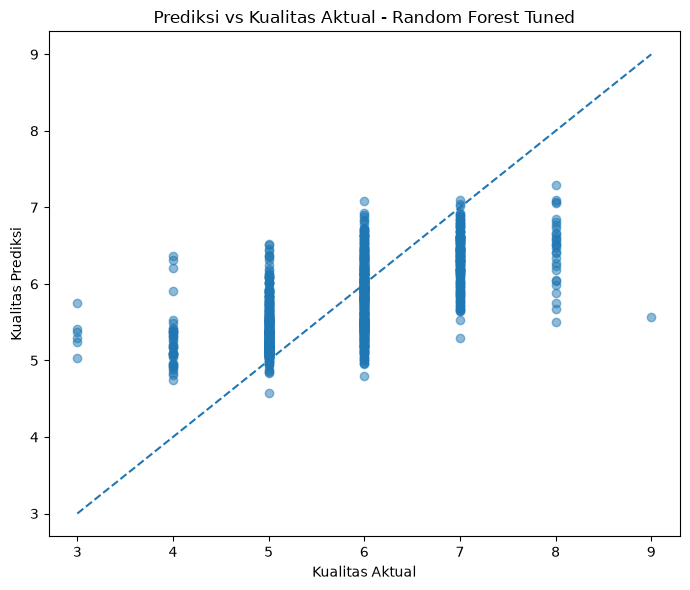

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_best_rf,
    alpha=0.5
)

# Garis prediksi ideal: prediksi = nilai aktual
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Kualitas Aktual")
plt.ylabel("Kualitas Prediksi")
plt.title("Prediksi vs Kualitas Aktual - Random Forest Tuned")
plt.tight_layout()
plt.show()


### Kesimpulan Prediksi Kualitas Wine

Eksperimen prediksi kualitas wine dilakukan menggunakan tiga algoritma regresi, yaitu Linear Regression, Decision Tree Regressor, dan Random Forest Regressor. Evaluasi awal menunjukkan bahwa Random Forest memberikan performa terbaik berdasarkan nilai MAE, RMSE, dan R². Selanjutnya, dilakukan hyperparameter tuning menggunakan RandomizedSearchCV dengan skema 5-Fold Cross-Validation untuk memperoleh konfigurasi model yang lebih optimal.

Model Random Forest Tuned memperoleh MAE sebesar 0,5265, RMSE sebesar 0,6807, dan R² sebesar 0,4019 pada data uji. Dibandingkan model Random Forest awal, hasil tersebut menunjukkan penurunan MAE dan RMSE serta peningkatan R². Dengan demikian, tuning memberikan peningkatan performa, meskipun besarnya peningkatan relatif terbatas.

Analisis kesalahan berdasarkan nilai kualitas aktual menunjukkan bahwa model memberikan prediksi yang lebih baik pada kualitas 5 dan 6, yang merupakan kelompok dengan jumlah sampel terbanyak. Sebaliknya, prediksi pada kualitas ekstrem, khususnya kualitas 3, 8, dan 9, memiliki kesalahan yang lebih besar. Visualisasi perbandingan prediksi dan nilai aktual juga menunjukkan kecenderungan model untuk memprediksi kualitas rendah terlalu tinggi dan kualitas tinggi terlalu rendah.

Secara keseluruhan, Random Forest Tuned merupakan model dengan performa terbaik di antara model yang diuji dalam eksperimen ini. Namun, kemampuan prediksinya masih terbatas, sebagaimana ditunjukkan oleh nilai R² sebesar 0,4019. Penelitian selanjutnya dapat mempertimbangkan penanganan ketidakseimbangan distribusi target, pengembangan fitur, dan pengujian algoritma regresi lain untuk meningkatkan performa prediksi kualitas wine.

In [34]:

from pathlib import Path
import joblib

# Menentukan lokasi penyimpanan model
project_dir = Path(r"D:\MachineLearning\Wine")
model_dir = project_dir / "models"

# Membuat folder jika belum tersedia
model_dir.mkdir(parents=True, exist_ok=True)

# Mengambil model dengan parameter terbaik hasil tuning
best_rf = rf_search.best_estimator_

# Menyimpan model
model_path = model_dir / "random_forest_quality.joblib"
joblib.dump(best_rf, model_path)

print("Model berhasil disimpan!")
print(f"Lokasi: {model_path}")
print(f"Parameter terbaik: {rf_search.best_params_}")


Model berhasil disimpan!
Lokasi: D:\MachineLearning\Wine\models\random_forest_quality.joblib
Parameter terbaik: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 25}


In [35]:

# Memuat model dari file
loaded_model = joblib.load(model_path)

# Membuat prediksi menggunakan model yang dimuat kembali
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Lima prediksi pertama:")
print(sample_predictions)

print("\nLima nilai kualitas aktual:")
print(y_test.iloc[:5].to_numpy())


Lima prediksi pertama:
[5.46077381 6.59495635 6.13470238 6.27527183 5.38016874]

Lima nilai kualitas aktual:
[5 6 6 7 5]


In [36]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prediksi dari model hasil tuning dan model yang dimuat
pred_original = best_rf.predict(X_test)
pred_loaded = loaded_model.predict(X_test)

# Periksa apakah prediksi keduanya identik
same_predictions = np.allclose(pred_original, pred_loaded)

print("Prediksi model konsisten:", same_predictions)

# Evaluasi model yang dimuat
final_metrics = pd.DataFrame([{
    "Model": "Random Forest Tuned",
    "MAE": mean_absolute_error(y_test, pred_loaded),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred_loaded)),
    "R2": r2_score(y_test, pred_loaded)
}])

display(final_metrics.round(4))


Prediksi model konsisten: True


,Model,MAE,RMSE,R2
0,Random Forest Tuned,0.5265,0.6807,0.4019


### Kesimpulan Eksperimen

Berdasarkan eksperimen yang telah dilakukan, Random Forest Tuned dipilih sebagai model terbaik di antara algoritma regresi yang diuji untuk memprediksi kualitas wine. Model ini memperoleh MAE sebesar 0,5265, RMSE sebesar 0,6807, dan R² sebesar 0,4019 pada data uji.

Hyperparameter tuning memberikan peningkatan performa dibandingkan Random Forest awal. Namun, analisis per kualitas menunjukkan bahwa model masih mengalami kesulitan dalam memprediksi kualitas yang jumlah sampelnya terbatas, terutama kualitas ekstrem.

Model terbaik telah disimpan dalam format Joblib pada direktori `models/random_forest_quality.joblib` dan berhasil dimuat kembali untuk melakukan prediksi. Dengan demikian, eksperimen regresi telah mencakup persiapan data, pelatihan model, evaluasi, hyperparameter tuning, analisis kesalahan, dan penyimpanan model.

Hasil ini menunjukkan bahwa karakteristik fisikokimia dapat digunakan untuk memprediksi kualitas wine, tetapi performa model masih perlu ditingkatkan untuk menghasilkan prediksi yang lebih baik pada seluruh tingkat kualitas.